# ReviewLens - 02 Sentiment model (steps 13-16)
Goal: train a sentiment classifier on the review text, measure how good it is, compare it with the dataset's own labels, and save `predictions.csv` for the warehouse.

Input: `../data/reviews_for_nlp.csv` (made by the ETL).  Output: `../data/predictions.csv`, charts in `../docs/`.

In [15]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict, cross_val_score
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, cohen_kappa_score

sns.set_theme(style="whitegrid")
LABELS = ["Positive", "Neutral", "Negative"]
RANDOM = 42

## 1. Load the data

In [16]:
df = pd.read_csv("../data/reviews_for_nlp.csv")
df["review_clean"] = df["review_clean"].fillna("")
print(df.shape)
print(df.sentiment.value_counts())
df.head()

(3923, 6)
sentiment
Positive    2372
Negative     983
Neutral      568
Name: count, dtype: int64


,review_key,review_clean,sentiment,rating,is_spam,language
0,1,mil gya hai acha hai aur toota howa b nahi hai,Positive,1,0,Roman Urdu
1,2,aram sy pocket may aa jta hai aur quality b ac...,Positive,5,0,Roman Urdu
2,3,sb sy acha chez apki customer service bhot ach...,Positive,2,0,Roman Urdu
3,4,back cover acha hai sai cuts hai aur soft b ha...,Positive,3,0,Roman Urdu
4,5,shru may may thumb grip k khalif thi kyu k ext...,Negative,4,0,Roman Urdu


## 2. The model (step 13)
Text -> numbers with **TF-IDF** (a word is important if it is frequent in this review but rare overall).
We use two views of the text together: whole words (and word pairs), and character pieces. Character pieces help a lot with Roman Urdu, where the same word is spelled many ways (*acha / achha / accha*).
The classifier is **Logistic Regression** (`class_weight="balanced"` so the small Neutral class is not ignored).

In [17]:
def make_features():
    return FeatureUnion([
        ("word", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
        ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=3, sublinear_tf=True)),
    ])

def make_model(clf=None):
    return Pipeline([("tfidf", make_features()),
                     ("clf", clf or LogisticRegression(max_iter=3000, C=3, class_weight="balanced", random_state=RANDOM))])

X, y = df["review_clean"], df["sentiment"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM)
model = make_model().fit(X_tr, y_tr)
pred = model.predict(X_te)
print(f"Test accuracy : {accuracy_score(y_te, pred):.3f}")
print(f"Macro F1      : {f1_score(y_te, pred, average='macro'):.3f}")
print()
print(classification_report(y_te, pred, labels=LABELS, digits=3))

Test accuracy : 0.785
Macro F1      : 0.725

              precision    recall  f1-score   support

    Positive      0.895     0.827     0.860       474
     Neutral      0.568     0.588     0.578       114
    Negative      0.686     0.797     0.737       197

    accuracy                          0.785       785
   macro avg      0.716     0.737     0.725       785
weighted avg      0.795     0.785     0.788       785



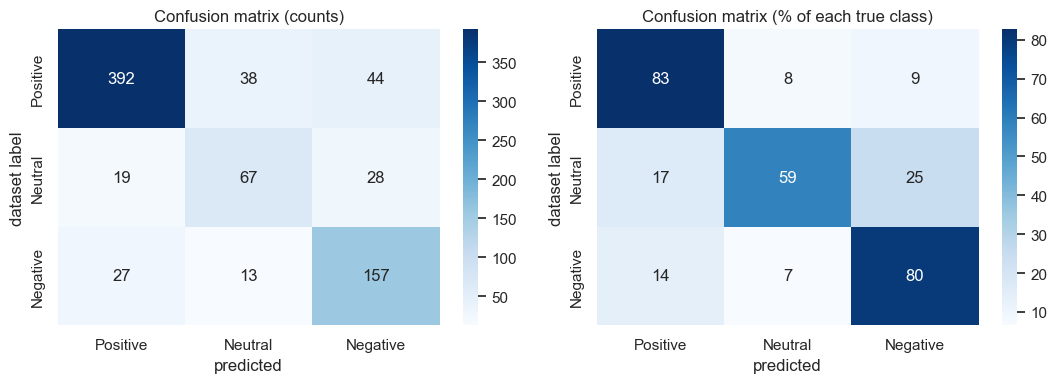

In [18]:
cm = confusion_matrix(y_te, pred, labels=LABELS)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=LABELS, yticklabels=LABELS, ax=ax[0])
ax[0].set_title("Confusion matrix (counts)"); ax[0].set_xlabel("predicted"); ax[0].set_ylabel("dataset label")
sns.heatmap(cm / cm.sum(axis=1, keepdims=True) * 100, annot=True, fmt=".0f", cmap="Blues", xticklabels=LABELS, yticklabels=LABELS, ax=ax[1])
ax[1].set_title("Confusion matrix (% of each true class)"); ax[1].set_xlabel("predicted"); ax[1].set_ylabel("dataset label")
plt.tight_layout(); plt.savefig("../docs/10_confusion_matrix.png", dpi=150, bbox_inches="tight"); plt.show()

Finding: The Logistic Regression model achieved 78.5% accuracy and a macro F1-score of 72.5% on the test dataset. Neutral sentiment was the hardest class to predict, with an F1-score of 57.8%, compared with 86.0% for Positive and 73.7% for Negative. The confusion matrix shows that the model sometimes misclassifies Neutral reviews as Positive or Negative, indicating difficulty in identifying ambiguous or mixed opinions

## 3. Compare three models (5-fold cross-validation)
A fair comparison uses cross-validation, not one lucky split. Naive Bayes is the classic model from your AI course.

In [19]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM)
candidates = {
    "Logistic Regression": make_model(),
    "Linear SVM":          make_model(LinearSVC(C=0.5, class_weight="balanced", random_state=RANDOM)),
    "Naive Bayes":         make_model(MultinomialNB(alpha=0.3)),
}
rows = []
for name, m in candidates.items():
    acc = cross_val_score(m, X, y, cv=skf, scoring="accuracy")
    f1m = cross_val_score(m, X, y, cv=skf, scoring="f1_macro")
    rows.append([name, acc.mean(), acc.std(), f1m.mean(), f1m.std()])
cmp_df = pd.DataFrame(rows, columns=["model", "accuracy", "acc_std", "macro_F1", "f1_std"]).round(3)
cmp_df

,model,accuracy,acc_std,macro_F1,f1_std
0,Logistic Regression,0.779,0.011,0.716,0.013
1,Linear SVM,0.786,0.011,0.714,0.013
2,Naive Bayes,0.725,0.007,0.561,0.008


Finding: Linear SVM achieved the highest accuracy of 78.6%, compared with 77.9% for Logistic Regression and 72.5% for Naive Bayes. However, the accuracy difference between Linear SVM and Logistic Regression was only 0.7 percentage points, which is smaller than their standard deviation of 1.1 percentage points. Therefore, Linear SVM and Logistic Regression can be considered statistically indistinguishable based on this comparison, while Naive Bayes performed noticeably worse.

## 4. What did the model learn? (most predictive words per class)

In [20]:
vec = TfidfVectorizer(ngram_range=(1, 1), min_df=3, sublinear_tf=True)
lr_words = LogisticRegression(max_iter=3000, C=3, class_weight="balanced", random_state=RANDOM).fit(vec.fit_transform(X), y)
names = np.array(vec.get_feature_names_out())
for i, cls in enumerate(lr_words.classes_):
    top = names[np.argsort(lr_words.coef_[i])[::-1][:12]]
    print(f"{cls:9s}", ", ".join(top))

Negative  bura, nahi, lekin, bekar, bekaar, bakwas, quality, toot, size, stuff, nah, hoti
Neutral   online, orignal, chahta, brand, kya, kyun, qubool, mukhtalif, who, hukum, masnoaat, hai
Positive  acha, bohat, behtareen, good, aur, shukriya, cheez, zabardast, daraz, pasand, theek, kamal


## 5. Predictions for EVERY review + the mismatch flag (steps 15-16)
If we predicted the reviews the model was trained on, it would look too good. So we use **out-of-fold** prediction: each review is predicted by a model that never saw it (5 folds).
`mismatch_flag = 1` when the model disagrees with the dataset label.

In [21]:
oof_proba = cross_val_predict(make_model(), X, y, cv=skf, method="predict_proba")
classes = np.array(sorted(y.unique()))                     # order used by predict_proba
out = pd.DataFrame({
    "review_key": df["review_key"],
    "predicted_label": classes[oof_proba.argmax(axis=1)],
    "confidence": oof_proba.max(axis=1).round(4),
})
out["dataset_label"] = df["sentiment"]
out["mismatch_flag"] = (out["predicted_label"] != out["dataset_label"]).astype(int)

print(f"Out-of-fold accuracy: {(1 - out.mismatch_flag.mean()):.3f}")
print(f"Mismatches: {out.mismatch_flag.sum()} of {len(out)} ({out.mismatch_flag.mean()*100:.1f}%)")
print("\nMismatch rate by dataset label:")
print((out.groupby("dataset_label").mismatch_flag.mean() * 100).round(1))
print("\nHigh-confidence disagreements (confidence >= 0.80):", ((out.mismatch_flag == 1) & (out.confidence >= 0.80)).sum())

Out-of-fold accuracy: 0.779
Mismatches: 867 of 3923 (22.1%)

Mismatch rate by dataset label:
dataset_label
Negative    27.3
Neutral     41.0
Positive    15.4
Name: mismatch_flag, dtype: float64

High-confidence disagreements (confidence >= 0.80): 119


In [22]:
# Look at the most confident disagreements by eye - are they model mistakes or wrong dataset labels?
look = out.merge(df[["review_key", "review_clean", "rating"]], on="review_key")
look = look[(look.mismatch_flag == 1)].sort_values("confidence", ascending=False).head(15)
for _, r in look.iterrows():
    print(f"[{r.review_key}] dataset={r.dataset_label:8s} model={r.predicted_label:8s} conf={r.confidence:.2f} stars={r.rating} | {r.review_clean[:110]}")

[1184] dataset=Neutral  model=Positive conf=1.00 stars=5 | acha hai
[1775] dataset=Neutral  model=Negative conf=0.98 stars=1 | jb b maa ne order kya mera wrong parsel aya jbke apke paas big size available hota ha phir b aap small size bh
[1771] dataset=Neutral  model=Negative conf=0.98 stars=1 | jb b maa ne order kya mera wrong parsel aya jbke apke paas big size available hota ha phir b aap small size bh
[3495] dataset=Negative model=Positive conf=0.98 stars=5 | wakai bohat acha masnoaat itni kaam dam may
[1478] dataset=Negative model=Positive conf=0.97 stars=4 | bohat acha cheez thi yar maine ye kahin bh nahi dekhi itni zabardast cheez hai yeh exercise ke liye poooray ke
[1016] dataset=Negative model=Neutral  conf=0.96 stars=1 | ye wo ny hay jo show kiya gaya hay sb change hay huuu
[1307] dataset=Neutral  model=Negative conf=0.96 stars=1 | kharab
[3220] dataset=Negative model=Neutral  conf=0.96 stars=4 | kia stand net mein moajood hai
[3052] dataset=Positive model=Negative conf=0.95 s

**Finding:** After manually examining the 15 highest-confidence disagreements, approximately 12 reviews appeared to have potentially incorrect dataset labels, while 3 appeared more likely to be model errors. Several reviews contained clearly positive or negative expressions but were assigned Neutral or the opposite sentiment in the original dataset. These findings provide evidence of possible inconsistencies in the original sentiment labels, particularly for Neutral reviews, although manual inspection alone cannot establish ground truth with certainty.

### Model vs star rating
Does the model agree with the stars more or less than the dataset label does?

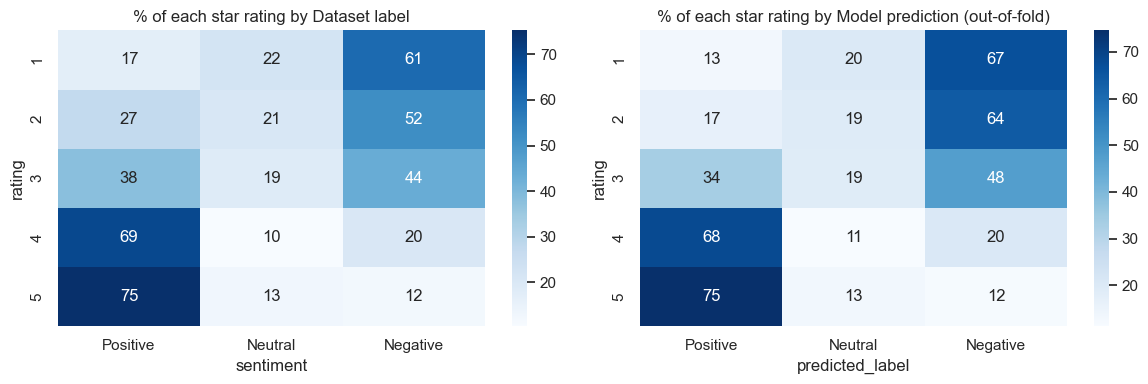

In [23]:
cmp = df[["review_key", "rating", "sentiment"]].merge(out[["review_key", "predicted_label"]], on="review_key")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, col, title in zip(ax, ["sentiment", "predicted_label"], ["Dataset label", "Model prediction (out-of-fold)"]):
    ct = pd.crosstab(cmp.rating, cmp[col], normalize="index")[LABELS] * 100
    sns.heatmap(ct, annot=True, fmt=".0f", cmap="Blues", ax=a); a.set_title(f"% of each star rating by {title}")
plt.tight_layout(); plt.savefig("../docs/11_rating_vs_label_vs_model.png", dpi=150, bbox_inches="tight"); plt.show()

## 6. Save `predictions.csv` for the warehouse (step 16)
`trust_score` is left as NULL for now (it is filled later if the fuzzy trust score is built).

In [24]:
final = out[["review_key", "predicted_label", "confidence", "mismatch_flag"]].copy()
final["trust_score"] = "NULL"
final.to_csv("../data/predictions.csv", index=False, lineterminator="\n")
print(final.shape); final.head()

(3923, 5)


,review_key,predicted_label,confidence,mismatch_flag,trust_score
0,1,Positive,0.4043,0,NULL
1,2,Positive,0.5112,0,NULL
2,3,Positive,0.7149,0,NULL
3,4,Positive,0.8327,0,NULL
4,5,Negative,0.5663,0,NULL


## 7. Hand-label a sample (step 14)
The dataset labels are not perfect. To measure how reliable they are, **you** label 100 reviews without seeing the dataset's answer or the model's answer.
1. Run the next cell. It creates `../docs/handlabel_sample.csv`.
2. Open it in Excel. Fill the `my_label` column with exactly **Positive**, **Neutral** or **Negative**. (About 30-40 minutes.)
3. Save as CSV, then run the cell after it.

In [25]:
import os
sample = df.sample(100, random_state=RANDOM)[["review_key", "review_clean", "sentiment"]].rename(columns={"sentiment": "dataset_label"})
sample = sample[["review_key", "review_clean"]].assign(my_label="")          # dataset label hidden on purpose
os.makedirs("../docs", exist_ok=True)
if os.path.exists("../docs/handlabel_sample.csv"):
    print("handlabel_sample.csv already exists - NOT overwritten (so your labels are safe).")
else:
    sample.to_csv("../docs/handlabel_sample.csv", index=False, encoding="utf-8-sig"); print("Created ../docs/handlabel_sample.csv")

handlabel_sample.csv already exists - NOT overwritten (so your labels are safe).


In [26]:
hl = pd.read_csv("../docs/handlabel_sample.csv")
hl["my_label"] = hl["my_label"].astype(str).str.strip().str.title().replace({"Nan": ""})
done = hl[hl.my_label.isin(LABELS)]
print(f"{len(done)} of {len(hl)} reviews labelled")
if len(done) < 50:
    print("Label at least 50 (ideally 100) reviews before reading these numbers.")
else:
    m = done.merge(df[["review_key", "sentiment"]], on="review_key").merge(out[["review_key", "predicted_label"]], on="review_key")
    print(f"\nDATASET label  vs  you : accuracy {accuracy_score(m.my_label, m.sentiment):.3f} | Cohen's kappa {cohen_kappa_score(m.my_label, m.sentiment):.3f}")
    print(f"MODEL (OOF)    vs  you : accuracy {accuracy_score(m.my_label, m.predicted_label):.3f} | Cohen's kappa {cohen_kappa_score(m.my_label, m.predicted_label):.3f}")
    print("\nDataset label vs your label (rows = you, columns = dataset):")
    print(pd.crosstab(m.my_label, m.sentiment).reindex(index=LABELS, columns=LABELS, fill_value=0))

100 of 100 reviews labelled

DATASET label  vs  you : accuracy 0.560 | Cohen's kappa 0.261
MODEL (OOF)    vs  you : accuracy 0.620 | Cohen's kappa 0.377

Dataset label vs your label (rows = you, columns = dataset):
sentiment  Positive  Neutral  Negative
my_label                              
Positive         38        9         6
Neutral          11        5         5
Negative          8        5        13


**Finding:** compare the two accuracies. If the model agrees with you more than the dataset label does, the dataset labels are noisier than the model - say that, with the numbers. A kappa of 0.6-0.8 is usually described as substantial agreement.